In [10]:
from torch.utils.data import Dataset
import pandas as pd
from pathlib import Path
from PIL import Image
import torch
import numpy as np
from torch.utils.data import DataLoader
from torchvision.transforms.functional import to_tensor
from sklearn.model_selection import train_test_split
import random
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt
import pickle
from collections import Counter
from torch.utils.data import Dataset
import random
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
ROOT_PATH = "data/faces_webface_112x112"

### Dataset

In [3]:
def preprocess_input(image):
    image /= 255.0 
    image -= 0.5
    image /= 0.5
    return image

In [4]:
def resize_image(image, size, letterbox_image):
    iw, ih  = image.size
    w, h    = size
    if letterbox_image:
        scale   = min(w/iw, h/ih)
        nw      = int(iw*scale)
        nh      = int(ih*scale)

        image   = image.resize((nw,nh), Image.BICUBIC)
        new_image = Image.new('RGB', size, (128,128,128))
        new_image.paste(image, ((w-nw)//2, (h-nh)//2))
    else:
        new_image = image.resize((w, h), Image.BICUBIC)
    return new_image

In [5]:
class PairDataset(Dataset):
    def __init__(self, dataset_path, images_are_bytes = False, width=112, height=112):
        dataset_path = ROOT_PATH + "/" + dataset_path
        with open(dataset_path, "rb") as f:
            data = pickle.load(f, encoding="bytes")
            self.images = data[0]
            self.labels = data[1]

        self.images_are_bytes = images_are_bytes
        self.width = width
        self.height = height 

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image1_data = self.images[index * 2]
        image2_data = self.images[index * 2 + 1]

        if not self.images_are_bytes:
            image1_data = image1_data.tobytes()
            image2_data = image2_data.tobytes()

        image1 = Image.open(BytesIO(image1_data)).convert("RGB")
        image2 = Image.open(BytesIO(image2_data)).convert("RGB")
        
        image1 = resize_image(image1, [self.width, self.height], letterbox_image = True)
        image2 = resize_image(image2, [self.width, self.height], letterbox_image = True)
        
        arr_image1 = np.transpose(preprocess_input(np.array(image1, np.float32)),[2, 0, 1])
        arr_image2 = np.transpose(preprocess_input(np.array(image2, np.float32)),[2, 0, 1])

        issame = bool(self.labels[index])
        
        return image1, image2, arr_image1, arr_image2, issame

In [8]:
agedb30_dataset = PairDataset("agedb_30.bin")

In [11]:
image1, image2, arr_image1, arr_image2, issame = agedb30_dataset[1020]

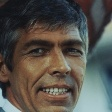

In [12]:
image1

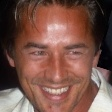

In [13]:
image2

In [14]:
arr_image1.shape, arr_image2.shape, arr_image1.min(), arr_image1.max()

((3, 112, 112), (3, 112, 112), np.float32(-0.94509804), np.float32(0.70980394))

In [15]:
issame

False

### Data Loader

In [16]:
batch_size = 32
num_workers = 1

In [18]:
def dataset_collate(batch):
    images_1 = []
    images_2 = []
    targets = []

    for _, _, arr_image1, arr_image2, issame in batch:
        images_1.append(arr_image1)
        images_2.append(arr_image2)
        targets.append(int(issame))

    images_1 = torch.from_numpy(np.array(images_1)).float()
    images_2 = torch.from_numpy(np.array(images_2)).float()
    targets = torch.tensor(targets, dtype=torch.long)

    return images_1, images_2, targets

In [26]:
agedb30_loader =  DataLoader(
    agedb30_dataset, 
    shuffle=True, 
    batch_size=batch_size, 
    num_workers=num_workers, 
    pin_memory=True,
    collate_fn=dataset_collate, 
)

In [27]:
images_1, images_2, targets = next(iter(agedb30_loader))

In [28]:
images_1.shape, images_2.shape, targets.shape

(torch.Size([32, 3, 112, 112]),
 torch.Size([32, 3, 112, 112]),
 torch.Size([32]))

In [35]:
targets

tensor([0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1,
        1, 0, 1, 1, 0, 0, 1, 1])

### Reverse Checking

In [30]:
def reverse_preprocess_input(image):
    image = (image * 0.5 + 0.5) * 255.0
    image = image.clamp(0, 255).byte()
    image = image.permute(1, 2, 0).cpu().numpy()
    return Image.fromarray(image)

In [40]:
idx = 3

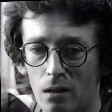

In [41]:
reverse_preprocess_input(images_1[idx])

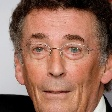

In [37]:
reverse_preprocess_input(images_2[idx])

In [42]:
targets[idx]

tensor(1)